# import

In [26]:
import h5py
import numpy as np

FILE_PATH = "/Users/kyu/Downloads/training_broadband_data_20260411_142911.h5"

with h5py.File(FILE_PATH, "r") as f:
    raw = f["acquisition/ElectricalSeries"][:]
    t_ns = f["acquisition/timestamp_ns"][:]  # optional, can ignore

n_time = len(t_ns)
n_ch = len(raw) // n_time

data = raw.reshape(n_time, n_ch)   # no timestamp here

X_signal = data[:, :-12]
X_aux = data[:, -12:]

fs = 31_000

print("signal shape:", X_signal.shape)
print("aux shape:", X_aux.shape)

signal shape: (4688544, 64)
aux shape: (4688544, 12)


In [24]:
import numpy as np
from scipy.signal import butter, sosfilt

fs = 31_000
fs_target = 1_000
down = 31

# choose cutoff below new Nyquist
cutoff = 100  # Hz

# causal lowpass
sos = butter(6, cutoff, btype="low", fs=fs, output="sos")

# causal filtering
X_signal_filt = sosfilt(sos, X_signal, axis=0)
X_aux_filt    = sosfilt(sos, X_aux,    axis=0)

# decimate
X_signal_ds = X_signal_filt[::down]
X_aux_ds    = X_aux_filt[::down]

t_ds = np.arange(X_signal_ds.shape[0]) / fs_target

print("signal_ds:", X_signal_ds.shape)
print("aux_ds:", X_aux_ds.shape)

signal_ds: (151244, 64)
aux_ds: (151244, 12)


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch, iirnotch, filtfilt

def auto_notch_filter_with_plot(
    data,
    fs=1000,
    search_band=(55, 65),
    Q=30.0,
    num_channels=3,
    seed=None,
    xlim=(0, 200),
):
    """
    Detect the strongest narrowband noise peak in `search_band`,
    apply a notch filter there across all channels,
    and plot Welch PSD before/after for a few channels.

    Parameters
    ----------
    data : pd.DataFrame or np.ndarray
        Time x Channels
    fs : float
        Sampling rate in Hz
    search_band : tuple
        Frequency band in which to search for line noise peak
    Q : float
        Notch quality factor
    num_channels : int
        Number of channels to plot
    seed : int or None
        Random seed for channel selection
    xlim : tuple
        Frequency axis limits for PSD plots

    Returns
    -------
    filtered_data : np.ndarray
        Time x Channels filtered array
    notch_freq : float
        Detected notch frequency
    """

    # convert to DataFrame, preserving Time x Channels
    if isinstance(data, np.ndarray):
        data = pd.DataFrame(data, columns=[f"ch_{i}" for i in range(data.shape[1])])
    elif not isinstance(data, pd.DataFrame):
        raise TypeError("data must be a pandas DataFrame or a numpy array")

    rng = np.random.default_rng(seed)

    channel_names = data.columns.to_list()
    selected_channels = rng.choice(
        channel_names,
        size=min(num_channels, len(channel_names)),
        replace=False
    )

    # average across channels to detect shared line noise
    avg_signal = data.mean(axis=1).to_numpy()

    nperseg = min(len(avg_signal), int(fs * 2))
    f, Pxx = welch(avg_signal, fs=fs, nperseg=nperseg)

    mask = (f >= search_band[0]) & (f <= search_band[1])
    if not np.any(mask):
        raise ValueError("search_band does not overlap Welch frequencies")

    notch_freq = f[mask][np.argmax(Pxx[mask])]
    print(f"Detected notch frequency: {notch_freq:.2f} Hz")

    # design and apply notch across all channels
    b, a = iirnotch(notch_freq, Q, fs)
    filtered_array = filtfilt(b, a, data.to_numpy(), axis=0)
    filtered_data = pd.DataFrame(filtered_array, columns=data.columns, index=data.index)

    # plot before/after PSD
    fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

    for ch in selected_channels:
        x_raw = data[ch].to_numpy()
        x_filt = filtered_data[ch].to_numpy()

        f_raw, P_raw = welch(x_raw, fs=fs, nperseg=min(len(x_raw), int(fs * 2)))
        f_filt, P_filt = welch(x_filt, fs=fs, nperseg=min(len(x_filt), int(fs * 2)))

        axes[0].plot(f_raw, 10 * np.log10(P_raw + 1e-12), label=str(ch))
        axes[1].plot(f_filt, 10 * np.log10(P_filt + 1e-12), label=str(ch))

    for ax in axes:
        ax.axvspan(search_band[0], search_band[1], color="gray", alpha=0.2)
        ax.axvline(notch_freq, linestyle="--", alpha=0.7)
        ax.set_xlim(*xlim)
        ax.set_xlabel("Frequency (Hz)")
        ax.set_ylabel("Power (dB/Hz)")
        ax.grid(True, alpha=0.3)

    axes[0].set_title("Before notch")
    axes[1].set_title("After notch")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

    return filtered_data.to_numpy(), notch_freq

Detected notch frequency: 58.00 Hz


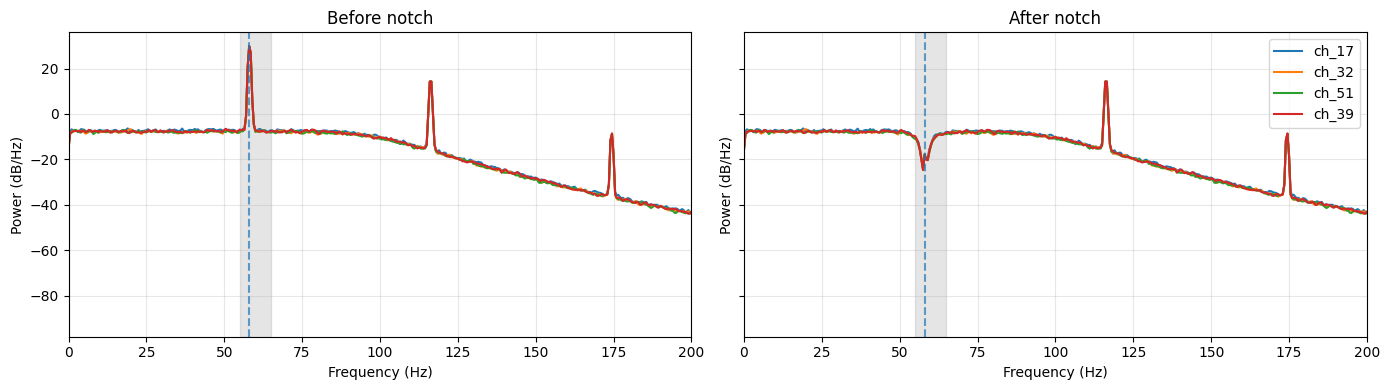

Detected notch frequency: 116.00 Hz


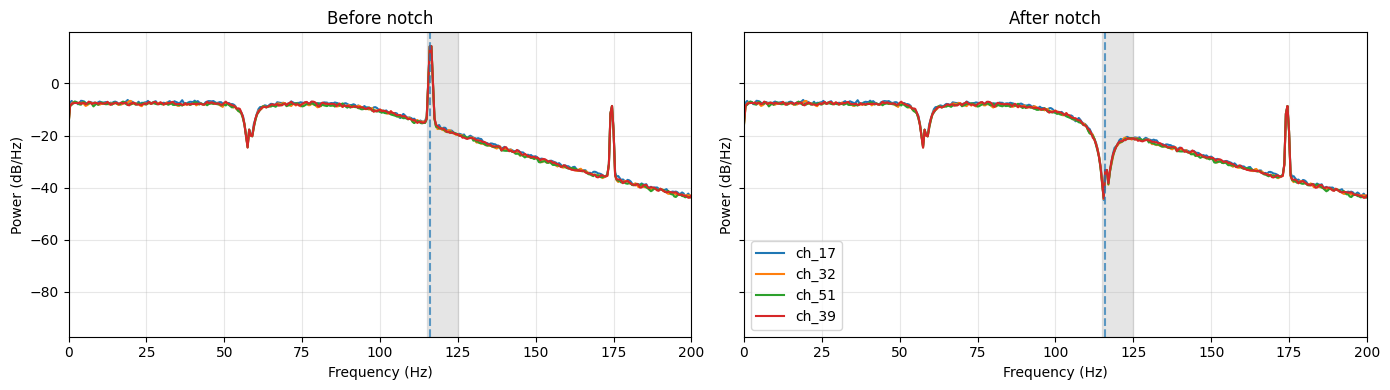

Detected notch frequency: 175.00 Hz


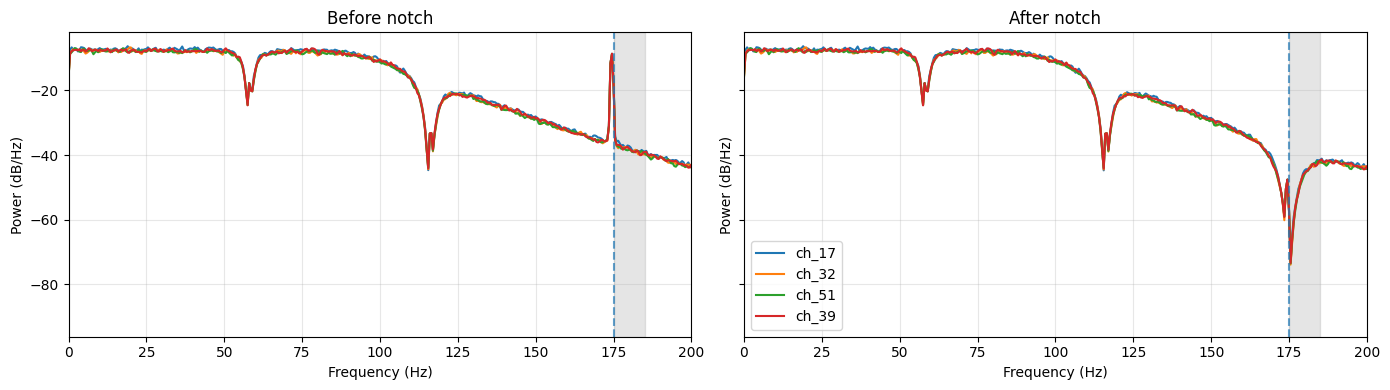

In [102]:
X_notched, notch_freq = auto_notch_filter_with_plot(
    X_signal_ds,
    fs=1000,
    search_band=(55, 65),
    Q=15,
    num_channels=4,
    seed=0
)

X_notched, notch_freq = auto_notch_filter_with_plot(
    X_notched,
    fs=1000,
    search_band=(115, 125),
    Q=15,
    num_channels=4,
    seed=0
)

X_notched, notch_freq = auto_notch_filter_with_plot(
    X_notched,
    fs=1000,
    search_band=(175, 185),
    Q=15,
    num_channels=4,
    seed=0
)

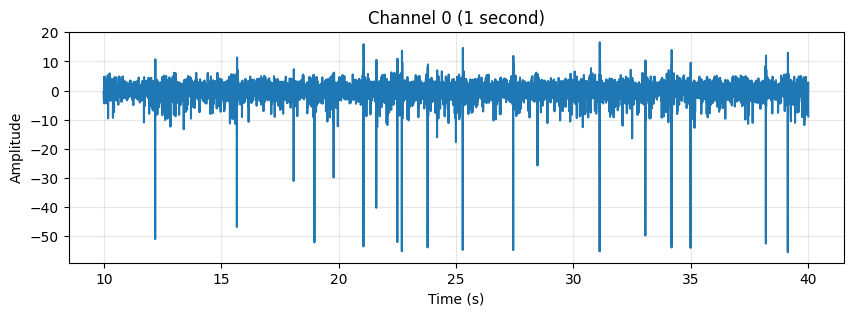

In [103]:
import matplotlib.pyplot as plt

fs = 1000  # your downsampled rate

ch = 0              # pick channel index
t_start = 10       # seconds
duration = 30        # 1 second

start = int(t_start * fs)
end = int((t_start + duration) * fs)

x = X_notched[start:end, ch]
t = (np.arange(start, end) / fs)

plt.figure(figsize=(10, 3))
plt.plot(t, x)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title(f"Channel {ch} (1 second)")
plt.grid(True, alpha=0.3)
plt.show()

In [108]:
import numpy as np
import kyunghwan_spike_functions as s


fs_raw = 31_000
fs_rate = 1_000

n_time, n_ch = X_notched.shape
n_time_rate = int(np.floor(n_time * fs_rate / fs_raw))

rate_mat = np.zeros((n_time_rate, n_ch))

for ch in range(n_ch):
    res = s.threshold_and_rate(
        X_notched[:, ch],
        fs_raw=fs_raw,
        fs_rate=fs_rate,
        k=3.5,
        mode="negative",
        refractory_s=0.001,
        smooth_method="none"
    )
    rate_mat[:, ch] = res["rate"]

print(rate_mat.shape)

TypeError: threshold_and_rate() got an unexpected keyword argument 'fs_raw'

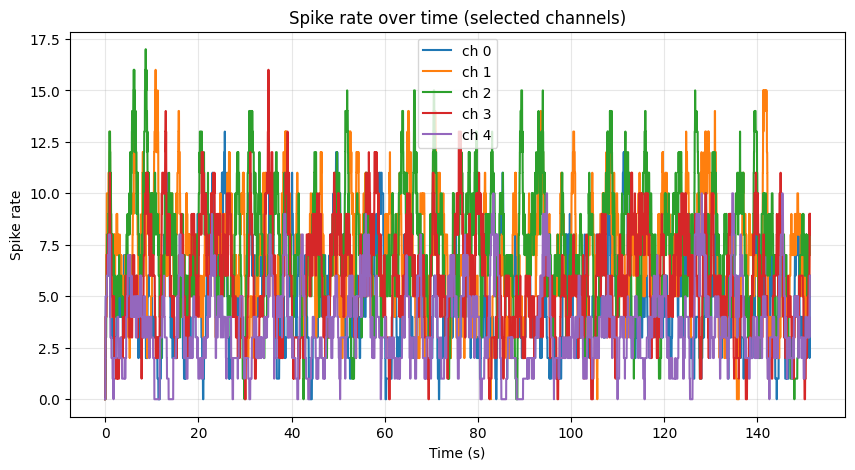

In [107]:
import numpy as np
import matplotlib.pyplot as plt

fs = 1000  # Hz
t = np.arange(rate_mat.shape[0]) / fs  # time in seconds

# choose a few channels
channels_to_plot = [0, 1, 2, 3, 4]  # change as needed

plt.figure(figsize=(10, 5))

for ch in channels_to_plot:
    plt.plot(t, rate_mat[:, ch], label=f'ch {ch}')

plt.xlabel('Time (s)')
plt.ylabel('Spike rate')
plt.title('Spike rate over time (selected channels)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [98]:
knobs = X_aux_ds[:, :4]
buttons = X_aux_ds[ :,4:]


In [99]:
import numpy as np

# z-score along time
knobs_z = (knobs - knobs.mean(axis=0)) / knobs.std(axis=0)
rates_z = (rate_mat - rate_mat.mean(axis=0)) / rate_mat.std(axis=0)

# correlation = (1/T) * X^T Y
T = knobs.shape[0]
corr = (knobs_z.T @ rates_z) / T   # shape: (K, C)

In [100]:
best_channel_per_knob = np.argmax(np.abs(corr), axis=1)

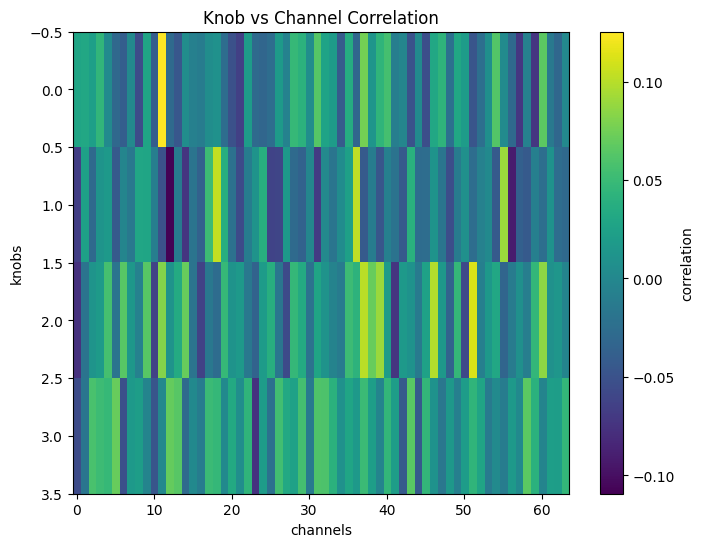

In [101]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.imshow(corr, aspect='auto')
plt.colorbar(label='correlation')
plt.xlabel('channels')
plt.ylabel('knobs')
plt.title('Knob vs Channel Correlation')
plt.show()